#Projeto da Disciplina Aplicação de Inteligência Artificial em Problema Real 🤖
------------------------------------------------------------------------------
## Desenvolvimento e Avaliação de Modelos de Machine Learning para Detecção de Doença Arterial Coronariana: Explicabilidade e Análise de Erros de Classificação 💔
------------------------------------------------------------------------------
### Projeto desenvolvido por:
####Ana Clara Gierse Raymundo: 10428453 👩
####Erica Gonçalves de Oliveira: 10428547 👩
####Luana Domingos Branco: 10428459 👩
####Victor Luiz de Sá Alves: 10426310 👨
------------------------------------------------------------------------------
### Síntese do conteúdo
#### Este arquivo fonte contém o código Python para execução da Análise exploratória de Dados (EDA) do dataset Z-Alizadeh Sani, incluindo verificação de integridade, estatísticas descritivas e visualização gráfica.

###Importação e configurações iniciais
#### Análise exploratória

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

sb.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

caminho_arquivo = '/content/Z-Alizadeh sani dataset.xlsx'

try:
    df = pd.read_excel(caminho_arquivo)
    print("✅ Arquivo .xlsx carregado com sucesso!")
except FileNotFoundError:
    print(f"❌ Arquivo não encontrado em '{caminho_arquivo}'. Verifique se fez o upload no painel lateral do Colab.")

✅ Arquivo .xlsx carregado com sucesso!


### Inspeção Geral e Qualidade dos Dados

In [ ]:
print("\n=== Informações do Dataset ===")
print(df.info())


print("\n=== Dimensões do Dataset ===")
print(f"Linhas (Pacientes): {df.shape[0]} | Colunas (Características): {df.shape[1]}")

print("\n=== Verificação de Dados Ausentes e Duplicados ===")
print(f"Total de valores nulos: {df.isnull().sum().sum()}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")


=== Informações do Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 56 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    303 non-null    int64  
 1   Weight                 303 non-null    int64  
 2   Length                 303 non-null    int64  
 3   Sex                    303 non-null    object 
 4   BMI                    303 non-null    float64
 5   DM                     303 non-null    int64  
 6   HTN                    303 non-null    int64  
 7   Current Smoker         303 non-null    int64  
 8   EX-Smoker              303 non-null    int64  
 9   FH                     303 non-null    int64  
 10  Obesity                303 non-null    object 
 11  CRF                    303 non-null    object 
 12  CVA                    303 non-null    object 
 13  Airway disease         303 non-null    object 
 14  Thyroid Disease        303

### Análise da Variável Alvo


=== Distribuição da Variável Alvo ('Cath') ===


,Frequência,Percentual (%)
Cath,,
Cad,216,71.29
Normal,87,28.71


/tmp/ipykernel_8092/604245700.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sb.countplot(data=df, x='Cath', palette='viridis')


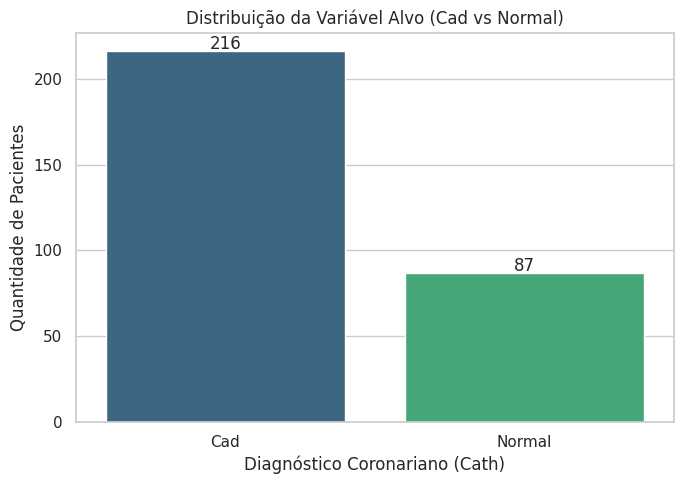

In [ ]:
print("\n=== Distribuição da Variável Alvo ('Cath') ===")
contagem_alvo = df['Cath'].value_counts()
percentual_alvo = df['Cath'].value_counts(normalize=True) * 100

df_alvo = pd.DataFrame({'Frequência': contagem_alvo, 'Percentual (%)': percentual_alvo.round(2)})
display(df_alvo)

plt.figure(figsize=(7, 5))
ax = sb.countplot(data=df, x='Cath', palette='viridis')
plt.title('Distribuição da Variável Alvo (Cad vs Normal)')
plt.xlabel('Diagnóstico Coronariano (Cath)')
plt.ylabel('Quantidade de Pacientes')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

### Relação entre Fatores de Risco Categóricos e Diagnóstico

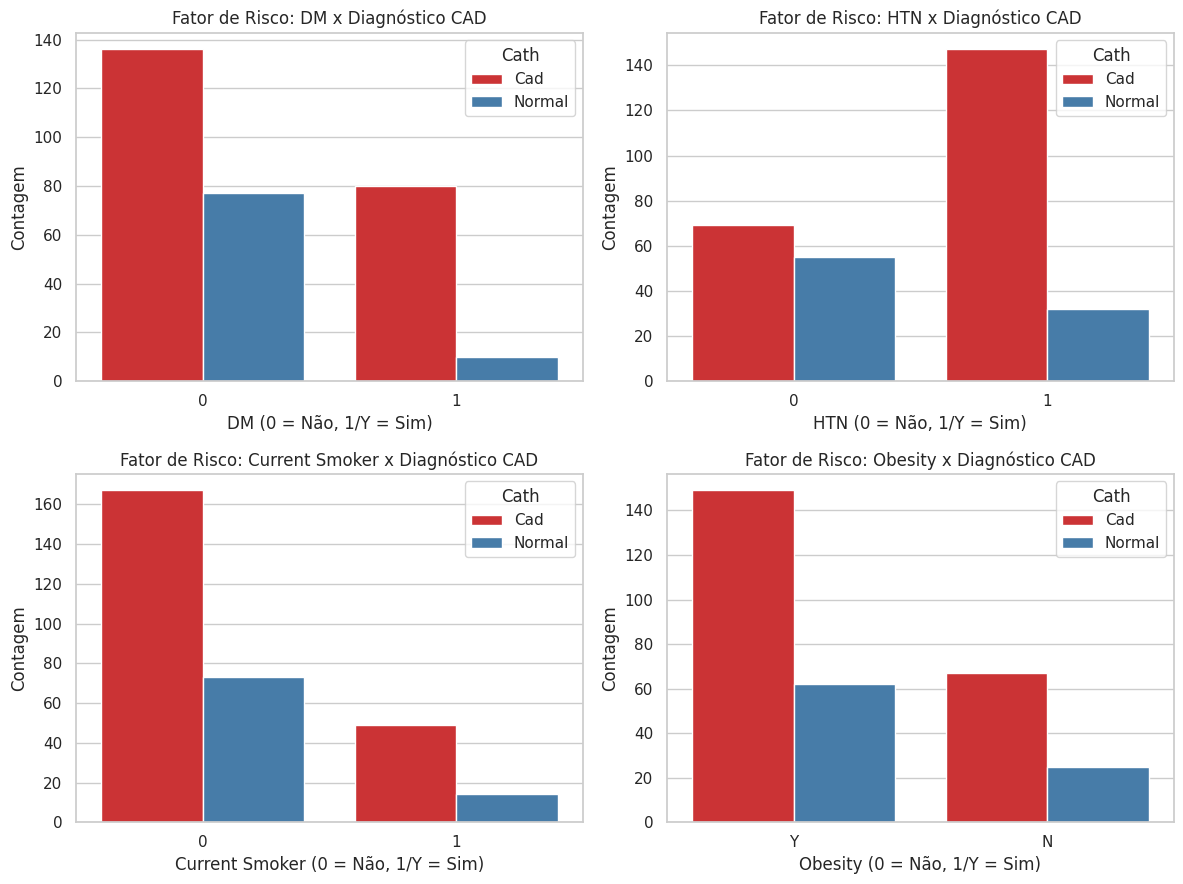

In [ ]:
fatores_risco = ['DM', 'HTN', 'Current Smoker', 'Obesity']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, col in enumerate(fatores_risco):
    sb.countplot(data=df, x=col, hue='Cath', palette='Set1', ax=axes[i])
    axes[i].set_title(f'Fator de Risco: {col} x Diagnóstico CAD')
    axes[i].set_xlabel(f'{col} (0 = Não, 1/Y = Sim)')
    axes[i].set_ylabel('Contagem')

plt.tight_layout()
plt.show()

### Matriz de Correlação das Variáveis Numéricas Chave

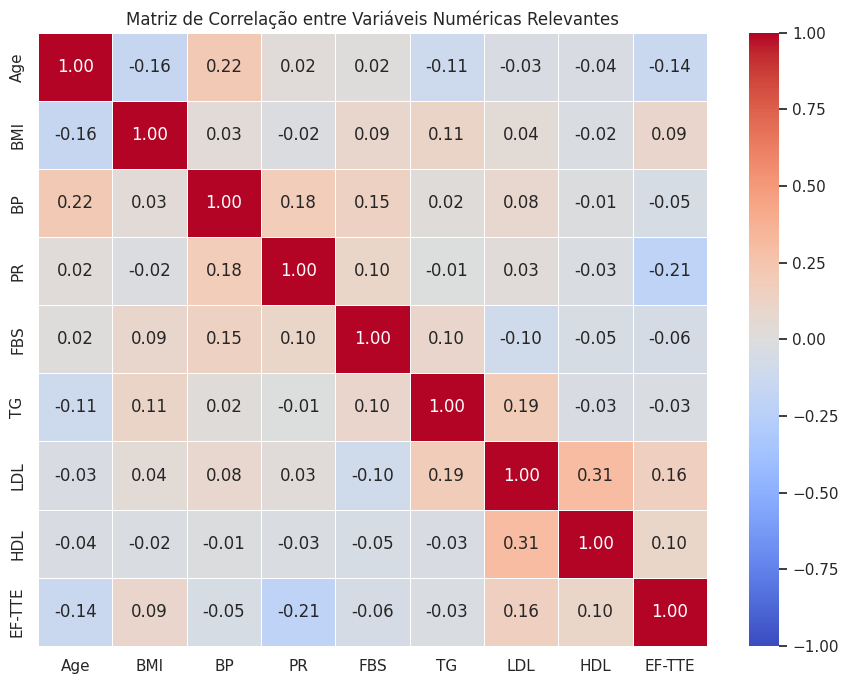

In [ ]:
cols_numericas = ['Age', 'BMI', 'BP', 'PR', 'FBS', 'TG', 'LDL', 'HDL', 'EF-TTE']

plt.figure(figsize=(9, 7))
matriz_corr = df[cols_numericas].corr()
sb.heatmap(matriz_corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação entre Variáveis Numéricas Relevantes')
plt.tight_layout()
plt.show()

### Análise de Distribuição e Outliers via Boxplot

/tmp/ipykernel_8092/2722079804.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df, x='Cath', y=col, palette='Set2', ax=axes[i], width=0.4)
/tmp/ipykernel_8092/2722079804.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df, x='Cath', y=col, palette='Set2', ax=axes[i], width=0.4)
/tmp/ipykernel_8092/2722079804.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df, x='Cath', y=col, palette='Set2', ax=axes[i], width=0.4)


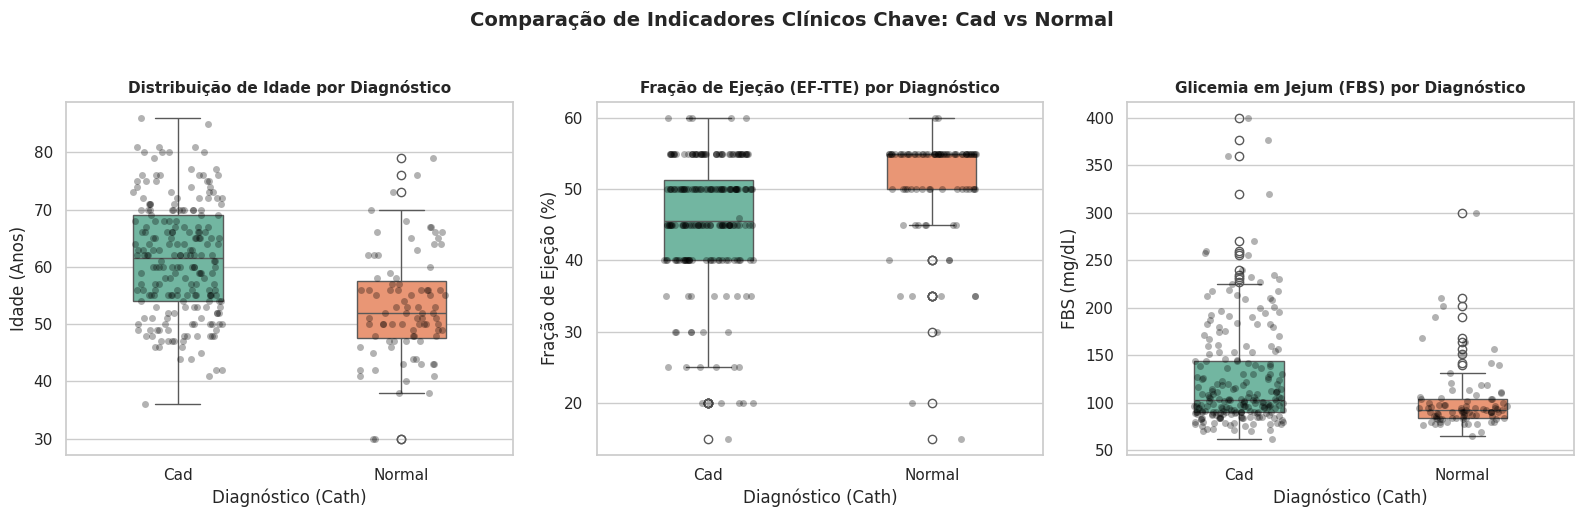

In [ ]:
cols_boxplot = ['Age', 'EF-TTE', 'FBS']
titulos = [
    'Distribuição de Idade por Diagnóstico',
    'Fração de Ejeção (EF-TTE) por Diagnóstico',
    'Glicemia em Jejum (FBS) por Diagnóstico'
]
ylabels = ['Idade (Anos)', 'Fração de Ejeção (%)', 'FBS (mg/dL)']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(cols_boxplot):
    sb.boxplot(data=df, x='Cath', y=col, palette='Set2', ax=axes[i], width=0.4)
    sb.stripplot(data=df, x='Cath', y=col, color='black', alpha=0.3, jitter=0.2, ax=axes[i])
    axes[i].set_title(titulos[i], fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Diagnóstico (Cath)')
    axes[i].set_ylabel(ylabels[i])

plt.suptitle('Comparação de Indicadores Clínicos Chave: Cad vs Normal', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

---

# Etapa N2 — Treinamento e avaliação dos modelos

Vamos utilizar Regressão Logística, SVM, Random Forest e XGBoost

## 1. Preparação dos dados

In [ ]:
# Conferindo as classes existentes na variável que queremos prever
print(df['Cath'].value_counts())
print(df['Cath'].unique())

Cath
Cad       216
Normal     87
Name: count, dtype: int64
['Cad' 'Normal']


Tranformação a variável Cath em valores numéricos. Neste projeto, CAD será a classe positiva (1) e Normal será a classe negativa (0).

In [ ]:
# Padronizando os textos para evitar problemas com espaços ou letras maiúsculas/minúsculas
alvo_texto = df['Cath'].astype(str).str.strip().str.lower()

# Identifica CAD como 1 e Normal como 0
y = alvo_texto.map(lambda valor: 1 if 'cad' in valor else (0 if 'normal' in valor else np.nan))

if y.isnull().any():
    raise ValueError("Existem valores em Cath que não foram reconhecidos. Confira as classes exibidas acima.")

X = df.drop(columns=['Cath']).copy()

print("Quantidade de pacientes:", len(df))
print("Distribuição da variável alvo:")
print(y.value_counts().rename(index={1: 'CAD', 0: 'Normal'}))

Quantidade de pacientes: 303
Distribuição da variável alvo:
Cath
CAD       216
Normal     87
Name: count, dtype: int64


## 2. Separação entre treino e teste

Vamos separar os dados em 80% para treinamento e 20% para teste.

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dados de treino:", X_treino.shape)
print("Dados de teste:", X_teste.shape)

Dados de treino: (242, 55)
Dados de teste: (61, 55)


Como existem variáveis numéricas e categóricas, vamos fazer o pré-processamento separadamente. Valores ausentes serão preenchidos pela mediana nas variáveis numéricas e pela categoria mais frequente nas categóricas. As variáveis categóricas serão codificadas e as numéricas serão padronizadas.

In [ ]:
# Separando os tipos de coluna
colunas_numericas = X_treino.select_dtypes(include=['int64', 'float64']).columns.tolist()
colunas_categoricas = X_treino.select_dtypes(exclude=['int64', 'float64']).columns.tolist()

preparo_numerico = Pipeline(steps=[
    ('imputacao', SimpleImputer(strategy='median')),
    ('escala', StandardScaler())
])

preparo_categorico = Pipeline(steps=[
    ('imputacao', SimpleImputer(strategy='most_frequent')),
    ('codificacao', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer(transformers=[
    ('numericas', preparo_numerico, colunas_numericas),
    ('categoricas', preparo_categorico, colunas_categoricas)
])

print("Variáveis numéricas:", len(colunas_numericas))
print("Variáveis categóricas:", len(colunas_categoricas))

Variáveis numéricas: 34
Variáveis categóricas: 21


## 3. Treinamento dos modelos

Vamos treinar quatro modelos. Para escolher os melhores parâmetros, utilizaremos GridSearchCV. O critério de escolha será o recall, pois queremos observar a capacidade do modelo de identificar pacientes que pertencem à classe CAD.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

modelos = {
    'Regressão Logística': (
        LogisticRegression(max_iter=2000, random_state=42),
        {
            'modelo__C': [0.1, 1, 10],
            'modelo__class_weight': [None, 'balanced']
        }
    ),
    'SVM': (
        SVC(probability=True, random_state=42),
        {
            'modelo__C': [0.1, 1, 10],
            'modelo__kernel': ['linear', 'rbf'],
            'modelo__class_weight': [None, 'balanced']
        }
    ),
    'Random Forest': (
        RandomForestClassifier(random_state=42),
        {
            'modelo__n_estimators': [100, 200],
            'modelo__max_depth': [None, 5, 10],
            'modelo__class_weight': [None, 'balanced']
        }
    ),
    'XGBoost': (
        XGBClassifier(
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        ),
        {
            'modelo__n_estimators': [100, 200],
            'modelo__max_depth': [3, 5],
            'modelo__learning_rate': [0.05, 0.1]
        }
    )
}

In [ ]:
resultados_modelos = {}
melhores_modelos = {}

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nome, (algoritmo, parametros) in modelos.items():
    print(f'\nTreinando: {nome}')

    pipeline = Pipeline(steps=[
        ('preprocessamento', preprocessador),
        ('modelo', algoritmo)
    ])

    busca = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring='recall',
        cv=validacao,
        n_jobs=-1
    )

    busca.fit(X_treino, y_treino)

    melhores_modelos[nome] = busca.best_estimator_
    resultados_modelos[nome] = {
        'melhores_parametros': busca.best_params_,
        'recall_validacao': busca.best_score_
    }

    print("Melhores parâmetros:", busca.best_params_)
    print("Recall médio na validação:", round(busca.best_score_, 4))


Treinando: Regressão Logística
Melhores parâmetros: {'modelo__C': 0.1, 'modelo__class_weight': None}
Recall médio na validação: 0.9126

Treinando: SVM
Melhores parâmetros: {'modelo__C': 0.1, 'modelo__class_weight': None, 'modelo__kernel': 'rbf'}
Recall médio na validação: 1.0

Treinando: Random Forest
Melhores parâmetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__n_estimators': 100}
Recall médio na validação: 0.9417

Treinando: XGBoost
Melhores parâmetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__n_estimators': 100}
Recall médio na validação: 0.9361


## 4. Avaliação dos modelos

Agora vamos avaliar os modelos no conjunto de teste, que não foi utilizado no treinamento.

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score,
    classification_report
)

resultados_teste = []
previsoes_modelos = {}

for nome, modelo in melhores_modelos.items():
    previsao = modelo.predict(X_teste)
    probabilidade = modelo.predict_proba(X_teste)[:, 1]

    matriz = confusion_matrix(y_teste, previsao, labels=[0, 1])
    vn, fp, fn, vp = matriz.ravel()

    especificidade = vn / (vn + fp) if (vn + fp) > 0 else 0

    resultados_teste.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_teste, previsao),
        'Precisão': precision_score(y_teste, previsao, zero_division=0),
        'Recall': recall_score(y_teste, previsao, zero_division=0),
        'Especificidade': especificidade,
        'F1-score': f1_score(y_teste, previsao, zero_division=0),
        'ROC-AUC': roc_auc_score(y_teste, probabilidade),
        'Falsos negativos': fn
    })

    previsoes_modelos[nome] = previsao

tabela_resultados = pd.DataFrame(resultados_teste).set_index('Modelo')
display(tabela_resultados.round(3))

,Acurácia,Precisão,Recall,Especificidade,F1-score,ROC-AUC,Falsos negativos
Modelo,,,,,,,
Regressão Logística,0.902,0.894,0.977,0.722,0.933,0.910,1
SVM,0.705,0.705,1.000,0.000,0.827,0.897,0
Random Forest,0.852,0.840,0.977,0.556,0.903,0.886,1
XGBoost,0.820,0.848,0.907,0.611,0.876,0.837,4


### Comparação das métricas

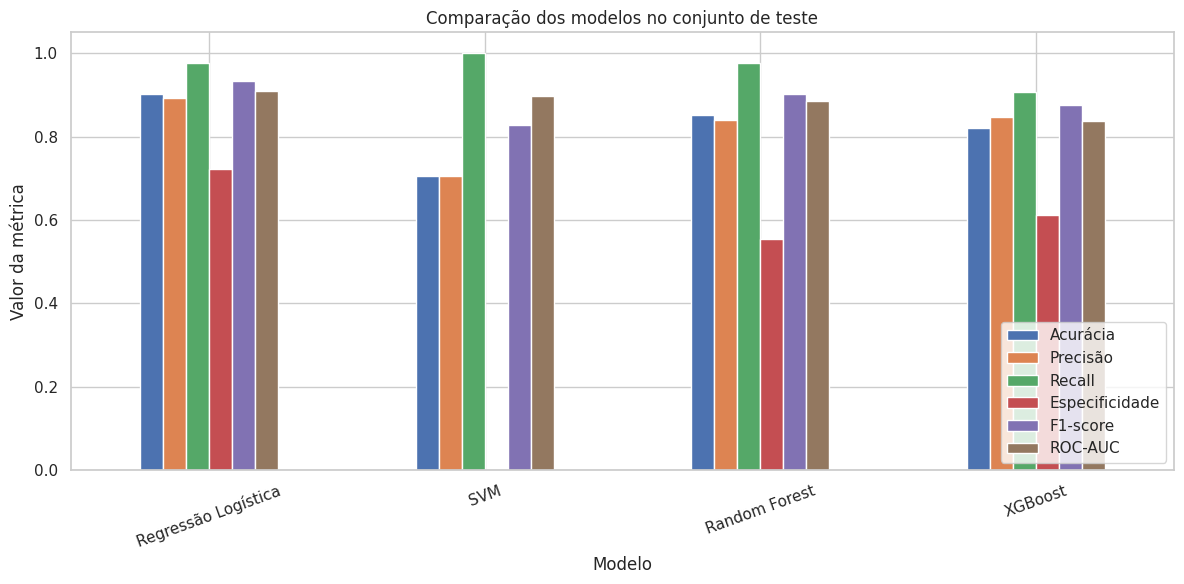

In [ ]:
tabela_resultados[['Acurácia', 'Precisão', 'Recall', 'Especificidade', 'F1-score', 'ROC-AUC']].plot(
    kind='bar',
    figsize=(12, 6)
)
plt.title('Comparação dos modelos no conjunto de teste')
plt.ylabel('Valor da métrica')
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 5. Matrizes de confusão e análise dos erros

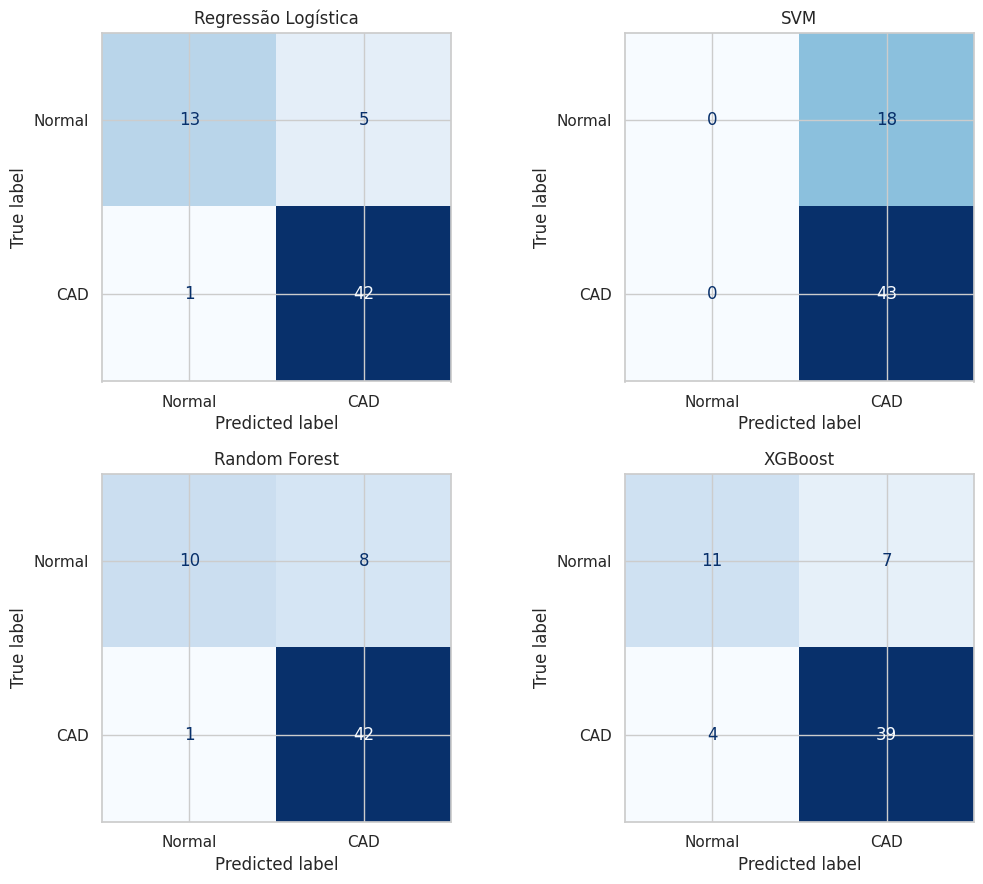

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for ax, (nome, previsao) in zip(axes, previsoes_modelos.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_teste,
        previsao,
        display_labels=['Normal', 'CAD'],
        cmap='Blues',
        ax=ax,
        colorbar=False
    )
    ax.set_title(nome)

plt.tight_layout()
plt.show()

In [ ]:
# Quantidade de falsos negativos de cada modelo
for nome, previsao in previsoes_modelos.items():
    matriz = confusion_matrix(y_teste, previsao, labels=[0, 1])
    vn, fp, fn, vp = matriz.ravel()

    print(f'{nome}:')
    print(f'  Falsos negativos (CAD classificado como Normal): {fn}')
    print(f'  Falsos positivos (Normal classificado como CAD): {fp}')
    print()

Regressão Logística:
  Falsos negativos (CAD classificado como Normal): 1
  Falsos positivos (Normal classificado como CAD): 5

SVM:
  Falsos negativos (CAD classificado como Normal): 0
  Falsos positivos (Normal classificado como CAD): 18

Random Forest:
  Falsos negativos (CAD classificado como Normal): 1
  Falsos positivos (Normal classificado como CAD): 8

XGBoost:
  Falsos negativos (CAD classificado como Normal): 4
  Falsos positivos (Normal classificado como CAD): 7



A análise abaixo mostra os pacientes do conjunto de teste que foram classificados incorretamente por cada modelo. Isso ajuda a observar quais casos podem estar sendo mais difíceis para os classificadores.

In [ ]:
# Mostrando os casos classificados incorretamente pelo melhor modelo em recall
melhor_nome = tabela_resultados['Recall'].idxmax()
melhor_previsao = previsoes_modelos[melhor_nome]

erros = X_teste.copy()
erros['Diagnóstico real'] = y_teste
erros['Diagnóstico previsto'] = melhor_previsao
erros = erros[erros['Diagnóstico real'] != erros['Diagnóstico previsto']]

print("Modelo com maior recall:", melhor_nome)
print("Quantidade de classificações incorretas:", len(erros))
display(erros.head(10))

Modelo com maior recall: SVM
Quantidade de classificações incorretas: 18


,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,...,Na,WBC,Lymph,Neut,PLT,EF-TTE,Region RWMA,VHD,Diagnóstico real,Diagnóstico previsto
214,66,62,185,Male,18.115413,0,0,0,0,0,...,138,7100,17,76,181,45,0,mild,0,1
296,42,63,163,Male,23.711845,0,0,0,0,1,...,141,8400,45,47,292,50,0,mild,0,1
151,62,80,156,Fmale,32.873110,0,1,0,0,0,...,142,6300,37,57,174,55,0,mild,0,1
254,48,89,155,Fmale,37.044745,0,0,0,0,0,...,143,6400,24,74,309,55,0,N,0,1
130,45,75,176,Male,24.212293,0,0,1,0,0,...,143,6800,43,46,223,40,0,mild,0,1
8,58,84,163,Fmale,31.615793,0,0,0,0,0,...,139,5100,49,50,370,50,0,N,0,1
287,56,62,154,Fmale,26.142688,0,0,0,0,0,...,138,5700,37,55,240,45,0,Moderate,0,1
258,56,82,178,Male,25.880571,0,0,0,0,0,...,141,9900,23,72,176,55,0,Moderate,0,1
183,66,65,140,Fmale,33.163265,0,1,0,0,0,...,144,9100,46,49,269,55,0,mild,0,1
280,49,66,167,Male,23.665244,0,0,1,0,0,...,142,17800,9,89,336,55,0,N,0,1
